1. Возьмите 2 ряда из материалов: стационарный и нестационарный.
2. Постройте прогноз для каждого с помощью каждой из моделей: MA, EMA, DEMA, TEMA
3. Оцените качество (метрика регрессии на ваш выбор MAE, MSE, RMSE), подобрав оптимальные параметры на первых месяцах ряда и спрогнозировав на последний, сравнив с истинными предсказаниями;
Определите оптимальную модель для каждого ряда и обоснуйте свой выбор.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Стационарный ряд:

In [2]:
daily_total_female_births_in_cal = pd.read_csv('../../Series/daily-total-female-births-in-cal.csv')['Count']

Не стационарный ряд:

In [3]:
monthly_boston_armed_robberies_j = pd.read_csv('../../Series/monthly-boston-armed-robberies-j.csv')['Count']

# MA:

In [4]:
def predict_ma(series, n, N_pred):

    series_copy = series.copy()

    for _ in range(N_pred):
        next_el = pd.Series(series_copy[-n:].mean())
        series_copy = pd.concat([series_copy, next_el], ignore_index = True)

    predict = series_copy[-N_pred:]

    with plt.style.context(style = 'bmh'):
        plt.figure(figsize = (12, 6))

        series.plot()
        predict.plot(c = 'r')

        plt.tight_layout()
        plt.show()

    return series_copy


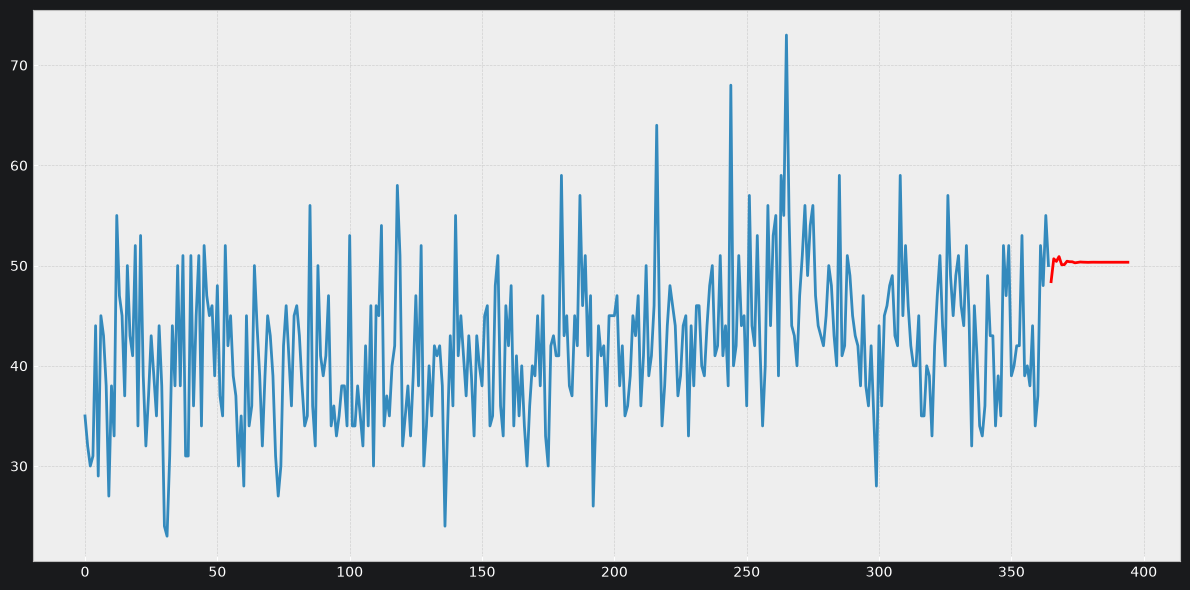

In [5]:
daily_total_female_births_in_cal_ma_predict = predict_ma(daily_total_female_births_in_cal, 5, 30)

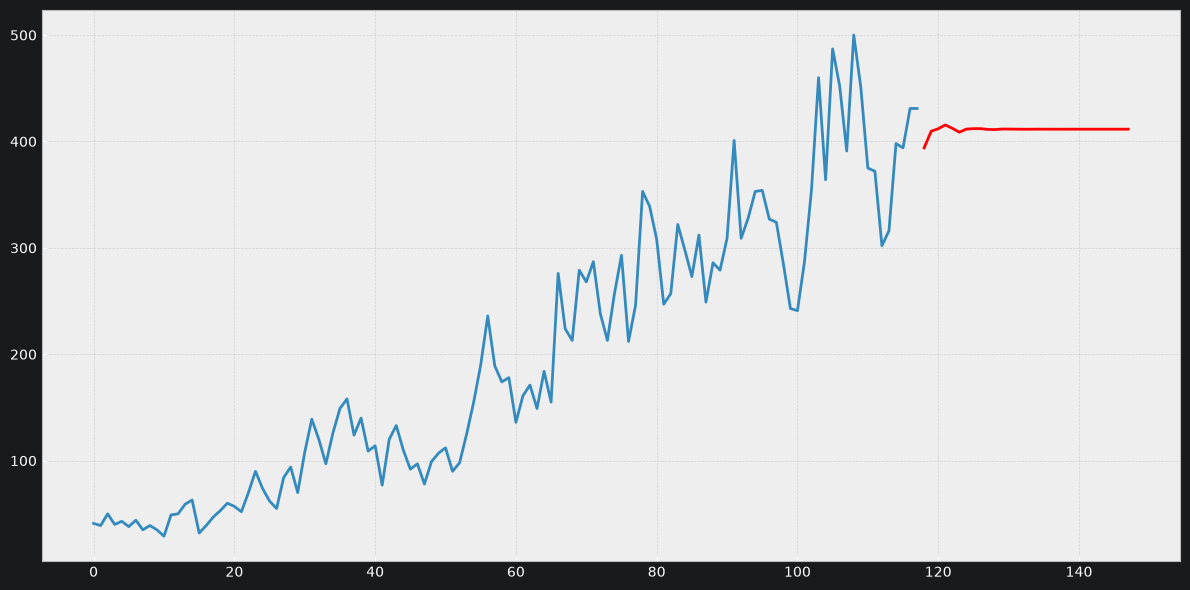

In [6]:
monthly_boston_armed_robberies_j_ma_predict = predict_ma(monthly_boston_armed_robberies_j, 5, 30)

# EMA: